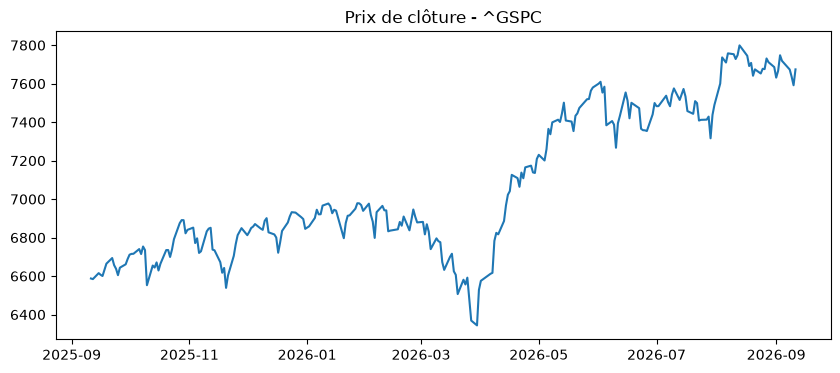

In [30]:
# Installation requise : pip install yfinance mlflow statsmodels scikit-learn
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import mlflow

# Extraction des données OHLCV
symbol = "^GSPC"
ticker = yf.Ticker(symbol)

# Données sur 10 ans
df = ticker.history(period="1y", interval="1d")

if not df.empty:
    df.index = df.index.tz_localize(None)
    df.rename(columns={'Open': 'open', 'High': 'high', 'Low': 'low', 'Close': 'close', 'Volume': 'volume'}, inplace=True)
    df = df[['open', 'high', 'low', 'close', 'volume']]
    
    plt.figure(figsize=(10, 4))
    plt.plot(df.index, df['close'])
    plt.title(f"Prix de clôture - {symbol}")
    plt.show()
else:
    print("Erreur lors du téléchargement des données.")

In [31]:
def getWeights_FFD(d, thres=1e-5):
    """Calcule les poids pour la différenciation fractionnaire (Fixed-width window)."""
    w = [1.]
    k = 1
    while True:
        w_ = -w[-1] / k * (d - k + 1)
        if abs(w_) < thres:
            break
        w.append(w_)
        k += 1
    return np.array(w[::-1]).reshape(-1, 1)

def fracDiff_FFD(series, d, thres=1e-5):
    """Applique la différenciation fractionnaire en préservant l'information."""
    w = getWeights_FFD(d, thres)
    width = len(w) - 1
    df_dict = {}
    for name in series.columns:
        seriesF = series[[name]].ffill().dropna()
        df_ = pd.Series(dtype=float, index=seriesF.index)
        for iloc1 in range(width, seriesF.shape[0]):
            loc0, loc1 = seriesF.index[iloc1 - width], seriesF.index[iloc1]
            if not np.isfinite(series.loc[loc1, name]):
                continue
            df_[loc1] = np.dot(w.T, seriesF.loc[loc0:loc1])[0, 0]
        df_dict[name] = df_.copy()
    return pd.concat(df_dict, axis=1).dropna()

# Recherche du d minimal optimal
out = pd.DataFrame(columns=['adfStat', 'pVal', 'corr'])
for d in np.linspace(0, 1, 11):
    df_ffd = fracDiff_FFD(df[['close']], d, thres=1e-4)
    if df_ffd.empty: 
        continue
    
    corr = np.corrcoef(df.loc[df_ffd.index, 'close'], df_ffd['close'])[0, 1]
    # Correction du warning ADF
    adf_res = adfuller(df_ffd['close'], maxlag=1, regression='c', autolag=None)
    out.loc[d] = [adf_res[0], adf_res[1], corr]

optimal_d = out[out['pVal'] < 0.05].index.min()
print(f"d optimal minimal trouvé pour la stationnarité : {optimal_d:.2f}")

# Application finale (Features)
df_features = fracDiff_FFD(df[['close']], optimal_d, thres=1e-3)
df_features.columns = [f"close_frac_{optimal_d:.2f}"]

C:\Users\pothfred\AppData\Local\Temp\ipykernel_29368\3792603756.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(df_ffd['close'], maxlag=1, regression='c', autolag=None)
C:\Users\pothfred\AppData\Local\Temp\ipykernel_29368\3792603756.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(df_ffd['close'], maxlag=1, regression='c', au

d optimal minimal trouvé pour la stationnarité : 0.50


In [32]:
def getIndMatrix(barIx, t1):
    """Matrice binaire de chevauchement des observations."""
    indM = pd.DataFrame(0, index=barIx, columns=range(t1.shape[0]))
    for i, (t0, t1_val) in enumerate(t1.items()):
        indM.loc[t0:t1_val, i] = 1
    return indM

def getAvgUniqueness(indM):
    """Calcule l'unicité moyenne de chaque label."""
    c = indM.sum(axis=1) # Concurrence
    u = indM.div(c, axis=0) # Unicité
    avgU = u[u > 0].mean() 
    return avgU
def seqBootstrap(indM, sLength=None):
    """Algorithme de Sequential Bootstrapping."""
    if sLength is None:
        sLength = indM.shape[1]
    phi = []
    while len(phi) < sLength:
        avgU = pd.Series(dtype=float)
        for i in indM.columns:
            indM_ = indM[phi + [i]]
            avgU.loc[i] = getAvgUniqueness(indM_).iloc[-1]
        prob = avgU / avgU.sum()
        choice = np.random.choice(indM.columns, p=prob)
        phi.append(choice)
    return phi
# Volatilité et barrières temporelles
volatility = df['close'].pct_change().ewm(span=100).std().dropna()

events = pd.DataFrame(index=volatility.index)
events['t1'] = events.index + pd.Timedelta(days=5)

# Label fictif : +1 si rendement futur > 0, sinon -1
future_returns = df['close'].shift(-5) / df['close'] - 1
events['label'] = np.sign(future_returns)
events.dropna(inplace=True)

# Alignement sécurisé initial
common_dates = df_features.index.intersection(events.index)
sample_events = events.loc[common_dates].copy()

# Calcul de l'unicité
indM = getIndMatrix(df.index, sample_events['t1'])
sample_events['weight'] = getAvgUniqueness(indM).values

In [33]:
# 1. Jointure stricte pour éviter tout KeyError ou désalignement
master_df = df_features.join(sample_events, how='inner').dropna()

X = master_df[[f"close_frac_{optimal_d:.2f}"]]
y = master_df['label']
weights = master_df['weight']

# 2. Séparation temporelle stricte (Train / Test)
split_idx = int(len(master_df) * 0.8)

# 1. Séparation temporelle stricte AVANT le bootstrap (Train / Test)
split_idx = int(len(master_df) * 0.8)

X_train_base = X.iloc[:split_idx]
y_train_base = y.iloc[:split_idx]

X_test, y_test = X.iloc[split_idx:], y.iloc[split_idx:]

# 2. Recalcul de la matrice d'unicité uniquement sur le Train Set pour éviter le blocage (plus rapide)
# On récupère les événements correspondants au train set
train_events = sample_events.loc[X_train_base.index]
indM_train = getIndMatrix(df.index, train_events['t1'])
# On filtre les colonnes de la matrice pour qu'elles correspondent exactement au train set
indM_train = indM_train.loc[:, range(len(train_events))]

# 3. Application du Sequential Bootstrap sur le train set
bootstrapped_indices = seqBootstrap(indM_train)

# 4. Extraction des données bootstrappées d'entraînement
X_train_boot = X_train_base.iloc[bootstrapped_indices]
y_train_boot = y_train_base.iloc[bootstrapped_indices]

# 5. Entraînement du modèle
with mlflow.start_run():
    mlflow.log_param("fractional_d", optimal_d)
    
    clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', max_depth=3, random_state=42)
    clf.fit(X_train_boot, y_train_boot)
    
    y_pred = clf.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred)
    
    mlflow.log_metric("test_accuracy", test_accuracy)
    mlflow.sklearn.log_model(clf, "model")
    
    print("--- Rapport de Classification (Out-of-Sample) ---")
    print(classification_report(y_test, y_pred))

2026/09/11 18:07:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


--- Rapport de Classification (Out-of-Sample) ---
              precision    recall  f1-score   support

        -1.0       0.60      0.25      0.35        24
         1.0       0.42      0.76      0.54        17

    accuracy                           0.46        41
   macro avg       0.51      0.51      0.45        41
weighted avg       0.53      0.46      0.43        41



In [34]:
# Alignement sécurisé des données X, y et des poids
X = df_features.loc[sample_events.index]
y = sample_events['label']
weights = sample_events['weight']

# Setup MLflow
mlflow.set_experiment("Tactical_Market_Prediction")

with mlflow.start_run():
    mlflow.log_param("fractional_d", optimal_d)
    
    # Utilisation d'un modèle ensembliste
    clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
    
    # L'algorithme apprend en accordant plus d'importance aux échantillons uniques
    clf.fit(X, y, sample_weight=weights)
    
    accuracy = clf.score(X, y)
    mlflow.log_metric("train_accuracy", accuracy)
    
    print(f"Précision de l'entraînement in-sample : {accuracy:.4f}")
    
    # Sauvegarde du modèle
    mlflow.sklearn.log_model(clf, "model")

2026/09/11 18:07:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Précision de l'entraînement in-sample : 1.0000


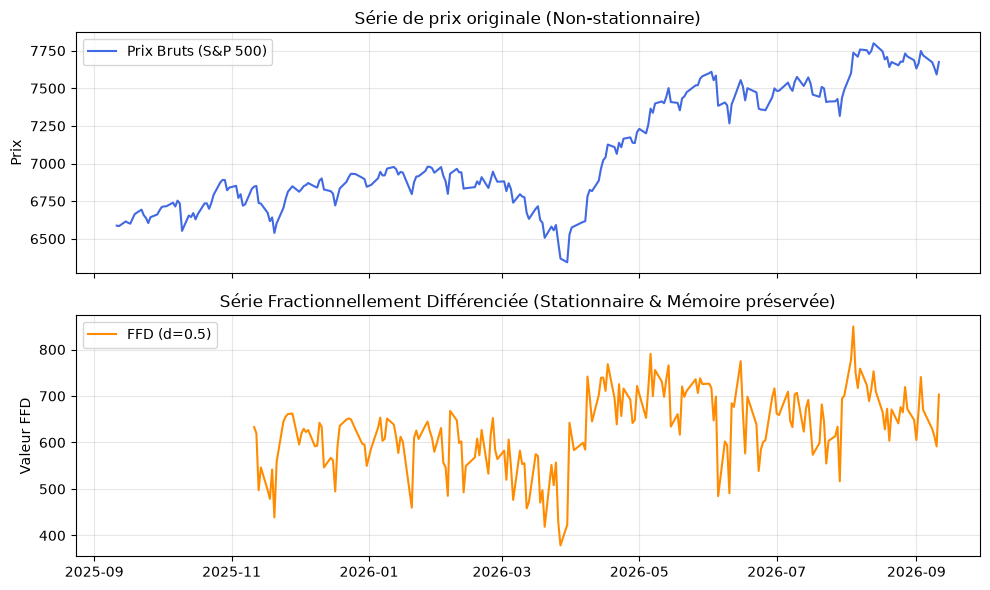

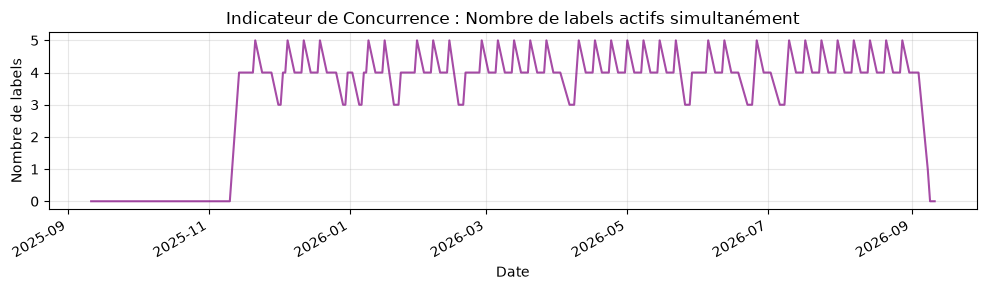

In [35]:
import matplotlib.pyplot as plt

# 1. Visualisation de la stationnarité FFD vs Prix Bruts
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(df.index, df['close'], label='Prix Bruts (S&P 500)', color='royalblue')
axes[0].set_title('Série de prix originale (Non-stationnaire)')
axes[0].set_ylabel('Prix')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_features.index, df_features.iloc[:, 0], label=f'FFD (d={optimal_d})', color='darkorange')
axes[1].set_title('Série Fractionnellement Différenciée (Stationnaire & Mémoire préservée)')
axes[1].set_ylabel('Valeur FFD')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Visualisation du chevauchement temporel (Concurrence Non-IID)
plt.figure(figsize=(10, 3))
indM.sum(axis=1).plot(color='purple', alpha=0.7)
plt.title('Indicateur de Concurrence : Nombre de labels actifs simultanément')
plt.ylabel('Nombre de labels')
plt.xlabel('Date')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

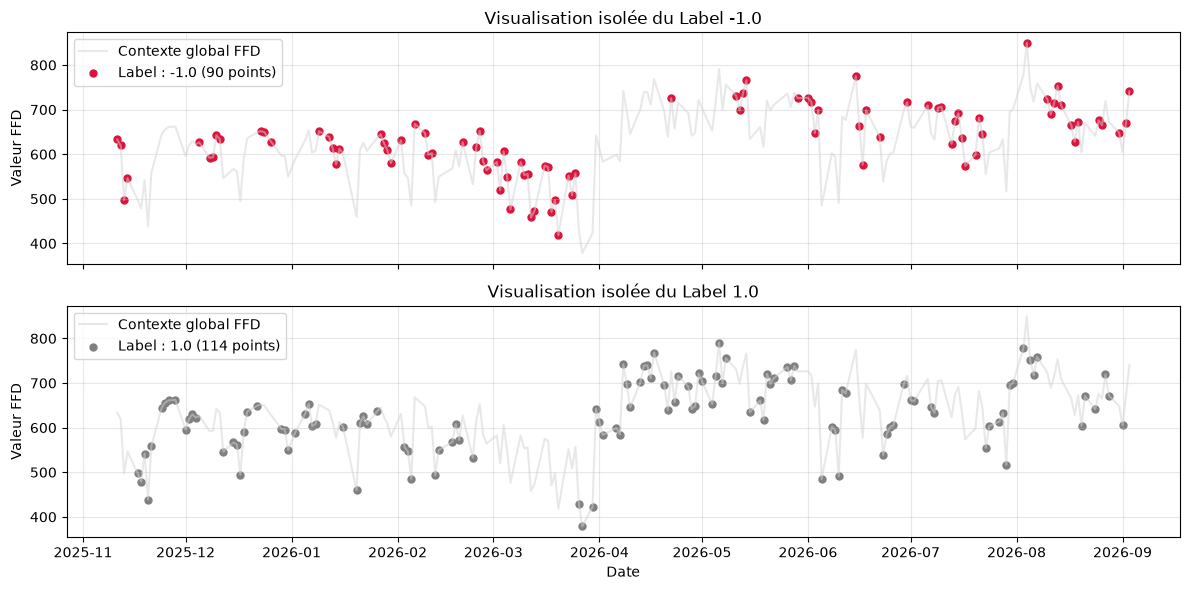

In [36]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Alignement et fusion des données FFD et des labels (sample_events)
# On s'assure d'avoir un DataFrame propre contenant la feature FFD et le label
eval_df = df_features.join(sample_events[['label']], how='inner').dropna()

# 2. Récupération des différents labels uniques présents
unique_labels = sorted(eval_df['label'].unique())

# 3. Création d'une figure avec autant de lignes que de labels uniques
fig, axes = plt.subplots(len(unique_labels), 1, figsize=(12, 3 * len(unique_labels)), sharex=True)

# Si on a un seul label (cas particulier), axes ne sera pas une liste
if len(unique_labels) == 1:
    axes = [axes]

colors = ['crimson', 'gray', 'forestgreen'] # Couleurs pour -1, 0, 1 par exemple

for idx, label_val in enumerate(unique_labels):
    ax = axes[idx]
    
    # Tracer toute la courbe en fond (grisée/transparente pour le contexte)
    ax.plot(eval_df.index, eval_df.iloc[:, 0], color='lightgray', alpha=0.5, label='Contexte global FFD')
    
    # Isoler uniquement les points correspondant au label actuel
    mask = (eval_df['label'] == label_val)
    subset = eval_df[mask]
    
    # Tracer les points du label spécifique
    ax.scatter(subset.index, subset.iloc[:, 0], color=colors[idx % len(colors)], s=25, label= f'Label : {label_val} ({len(subset)} points)')
    
    ax.set_title(f'Visualisation isolée du Label {label_val}')
    ax.set_ylabel('Valeur FFD')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

plt.xlabel('Date')
plt.tight_layout()
plt.show()

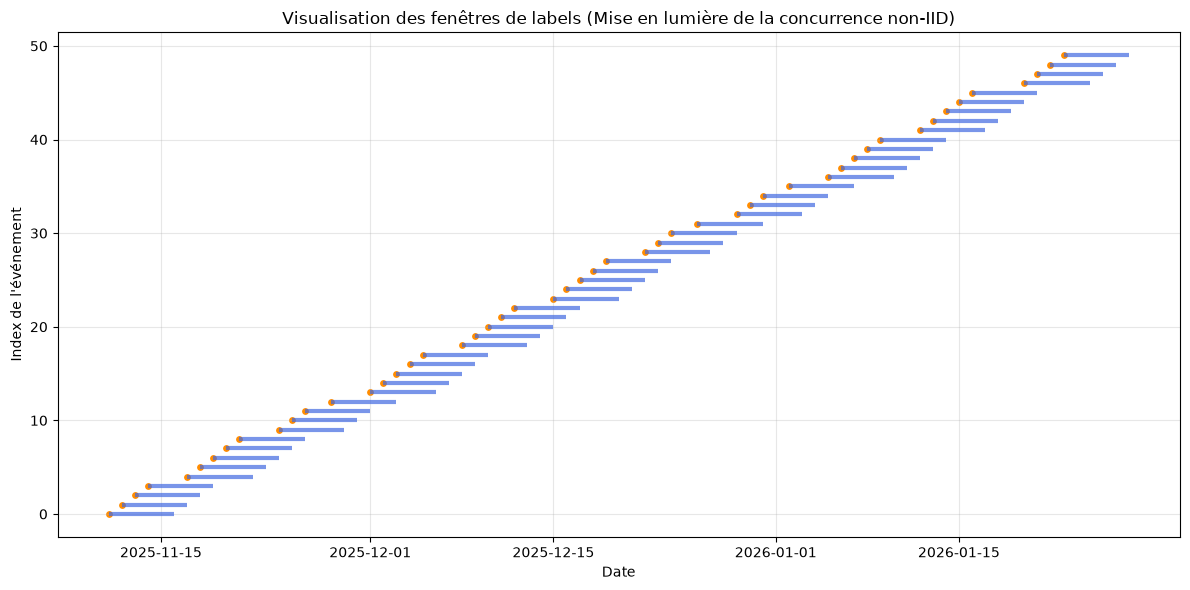

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Sélectionner un échantillon d'événements (par exemple les 50 premiers) pour que le graphique reste lisible
sample_subset = sample_events.head(50).reset_index()
# Renommer la colonne d'index en 't0' si nécessaire
sample_subset.rename(columns={sample_subset.columns[0]: 't0'}, inplace=True)

# 2. Création du graphique des fenêtres temporelles (concurrence)
plt.figure(figsize=(12, 6))

for i, row in sample_subset.iterrows():
    # On trace une ligne horizontale pour chaque label de sa date de début (t0) à sa date de fin (t1)
    plt.hlines(y=i, xmin=row['t0'], xmax=row['t1'], color='royalblue', alpha=0.7, linewidth=3)
    plt.scatter(row['t0'], i, color='darkorange', s=15) # Point de départ (t0)

plt.title("Visualisation des fenêtres de labels (Mise en lumière de la concurrence non-IID)")
plt.xlabel("Date")
plt.ylabel("Index de l'événement")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()